# Chemical abundances in HD209

In [1]:
import warnings
from functools import partial

import iris
import matplotlib.colors as mcol
import matplotlib.pyplot as plt
import numpy as np
import paths
from aeolus.calc import (
    integrate,
    last_n_day_mean,
    spatial,
    spatial_mean,
    toa_net_energy,
    zonal_mean,
)
from aeolus.const import init_const
from aeolus.coord import get_cube_rel_days, interp_cube_from_height_to_pressure_levels
from aeolus.lfric import fix_time_coord, load_lfric_raw, ugrid_spatial
from aeolus.model import lfric
from aeolus.plot import (
    figsave,
    map_scatter,
    timeseries_1d,
    timeseries_2d,
)
from common import (
    EXPERIMENTS,
    lfric_callback_uniform_height,
)

warnings.filterwarnings("ignore")
iris.FUTURE.date_microseconds = True

print(*EXPERIMENTS.keys(), sep="\n")

shj_c48_l32
shj_c24_l32
shj_c96_l32
shj_c48_l16
shj_c48_l64
dhj_c48_l66
dhj_c24_l66
dhj_c96_l66
dhj_c48_l66_s0p5_m90
dhj_c48_l66_s0p5_p90
hd209_dt30_nrad3
hd209_dt30_nrad4
hd209_dt30_nrad5
hd209_rand_t100k_nf20_tau1e5_amp1e-2_sclht6


In [2]:
exp_key = "hd209_dt30_nrad4"
ds_main = load_lfric_raw(
    "../../src/data/lfric/hd209/dt30_nrad4/lfric_diag_native_20000530-20000609.nc",
    callback=partial(
        lfric_callback_uniform_height,
        model_top_height=EXPERIMENTS[exp_key].const.domain_height.data,
    ),
)
print(ds_main)

0: air_pressure / (Pa)                 (time: 1; level_height: 67; -- : 13824)
1: air_temperature / (K)               (time: 1; level_height: 67; -- : 13824)
2: atmosphere_energy_content / (J m-2) (time: 1; -- : 13824)
3: atmosphere_horizontal_kinetic_energy_content / (J m-2) (time: 1; -- : 13824)
4: atmosphere_mass_of_air_per_unit_area / (kg m-2) (time: 1; -- : 13824)
5: atmosphere_potential_energy_content / (J m-2) (time: 1; -- : 13824)
6: atmosphere_vertical_kinetic_energy_content / (J m-2) (time: 1; -- : 13824)
7: axial_angular_momentum_at_cell_centres / (kg m2 s-1) (time: 1; level_height: 66; -- : 13824)
8: divergence_of_wind / (s-1)          (time: 1; level_height: 66; -- : 13824)
9: mass_fraction_of_ammonia_in_air / (kg kg-1) (time: 1; level_height: 67; -- : 13824)
10: mass_fraction_of_carbon_monoxide_in_air / (kg kg-1) (time: 1; level_height: 67; -- : 13824)
11: mass_fraction_of_cesium_in_air / (kg kg-1) (time: 1; level_height: 67; -- : 13824)
12: mass_fraction_of_helium_in_air

Text(0.5, 1.0, 'mass_fraction_of_methane_in_air')

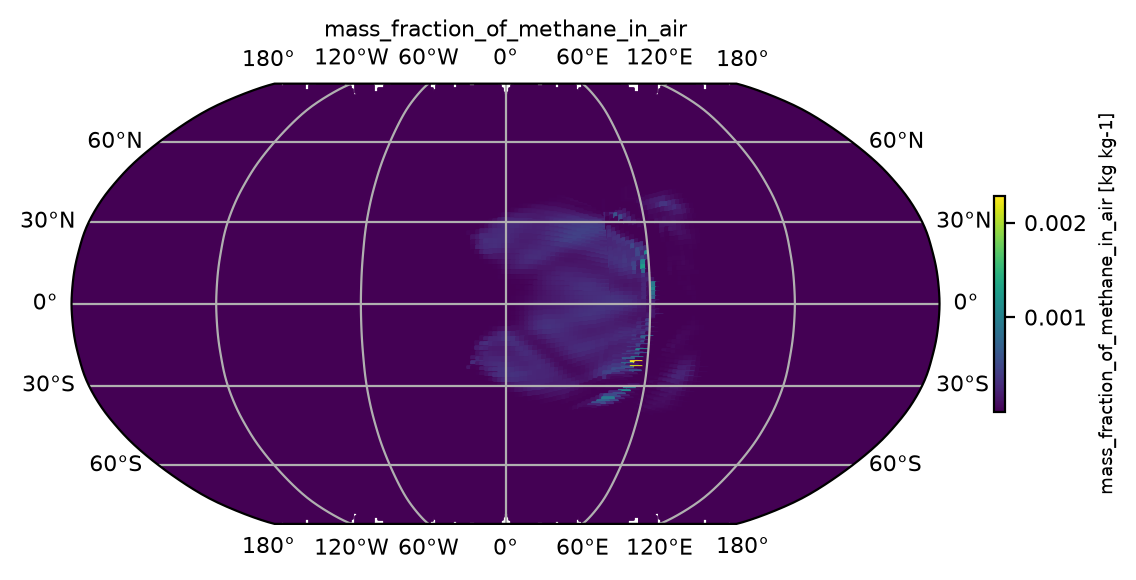

In [8]:
import cartopy.crs as ccrs

cube = ds_main.extract_cube("ch4")[-1, -5, ...]
lons = cube.coord(lfric.x).points
lats = cube.coord(lfric.y).points

fig = plt.figure()
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))
ax.set_global()
ax.gridlines(draw_labels=True)
mappable = ax.scatter(
    lons,
    lats,
    c=cube.data,
    s=16,
    marker="s",
    transform=ccrs.PlateCarree(),
    # norm=mcol.CenteredNorm(),
    # cmap="seismic",
)
fig.colorbar(
    mappable,
    ax=ax,
    orientation="vertical",
    shrink=0.4,
    label=f"{cube.name()} [{cube.units}]",
)
ax.set_title(cube.name())